In [1]:
!pip install pandas

In [2]:
import numpy as np
import pandas as pd

In [3]:
!pip install nibabel

In [4]:
!pip install opencv-python

In [5]:
!pip install tqdm scikit-learn -q


In [6]:
!pip install matplotlib

In [7]:
import os
import glob
import numpy as np
import nibabel as nib
import cv2
import csv
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

print('All imports OK')

All imports OK


In [13]:
BASE_DIR = r"C:\Users\FatmaH\dataset\PKG - RSNA-ASNR-MICCAI-BraTS-2021\RSNA-ASNR-MICCAI-BraTS-2021"
SAVE_DIR = r"C:\Users\FatmaH\dataset\Preprocessing-fatma"
# ─────────────────────────────────────────────────────────────────────────────

# Which split to process
# ValidationSet has no seg masks — use TrainingSet only
SPLIT = "BraTS2021_TrainingSet"

# 2D output size
IMG_SIZE = (256, 256)

# Skip slices where the mask is all background (recommended: True)
SKIP_EMPTY = True

# Modality channel order in the stacked array
# Index: 0=T1, 1=T1ce, 2=T2, 3=FLAIR
MODALITY_ORDER = ['t1', 't1ce', 't2', 'flair']

# Create output directories
RAW_IMG_DIR = os.path.join(SAVE_DIR, 'images_raw')
RAW_SEG_DIR = os.path.join(SAVE_DIR, 'masks_raw')
SLC_IMG_DIR = os.path.join(SAVE_DIR, 'images_2d')
SLC_SEG_DIR = os.path.join(SAVE_DIR, 'masks_2d')

for d in [RAW_IMG_DIR, RAW_SEG_DIR, SLC_IMG_DIR, SLC_SEG_DIR]:
    os.makedirs(d, exist_ok=True)

print(f'BASE_DIR : {BASE_DIR}')
print(f'SAVE_DIR : {SAVE_DIR}')
print(f'Split    : {SPLIT}')
print(f'Exists   : {os.path.isdir(BASE_DIR)}')

BASE_DIR : C:\Users\FatmaH\dataset\PKG - RSNA-ASNR-MICCAI-BraTS-2021\RSNA-ASNR-MICCAI-BraTS-2021
SAVE_DIR : C:\Users\FatmaH\dataset\Preprocessing-fatma
Split    : BraTS2021_TrainingSet
Exists   : True


In [14]:
def find_all_patients(base_dir, split):
    """
    Walk all source sub-folders inside the split directory.
    Returns list of (patient_id, patient_folder_path, source_name).
    
    Structure handled:
    BASE_DIR/
    └── BraTS2021_TrainingSet/
        ├── TCGA-GBM/
        │   └── BraTS2021_XXXXX/   ← patient folder
        ├── TCGA-LGG/
        └── ...
    """
    split_dir = os.path.join(base_dir, split)
    patients  = []

    if not os.path.isdir(split_dir):
        print(f'ERROR: split directory not found:\n  {split_dir}')
        return patients

    for source in sorted(os.listdir(split_dir)):
        source_path = os.path.join(split_dir, source)
        if not os.path.isdir(source_path):
            continue
        for patient_id in sorted(os.listdir(source_path)):
            patient_path = os.path.join(source_path, patient_id)
            if os.path.isdir(patient_path) and patient_id.startswith('BraTS2021'):
                patients.append((patient_id, patient_path, source))

    return patients


patients = find_all_patients(BASE_DIR, SPLIT)
print(f'Total patients found: {len(patients)}')
print()

# Show breakdown by source
from collections import Counter
source_counts = Counter(src for _, _, src in patients)
print('Patients per source:')
for src, count in sorted(source_counts.items()):
    print(f'  {src:<40} {count}')

Total patients found: 1251

Patients per source:
  ACRIN-FMISO-Brain                        4
  CPTAC-GBM                                33
  IvyGAP                                   30
  TCGA-GBM                                 102
  TCGA-LGG                                 65
  UCSF-PDGM                                263
  UPENN-GBM                                403
  new-not-previously-in-TCIA               351


In [15]:
# Pick the first patient and show what files it contains
sample_id, sample_path, sample_src = patients[0]

print(f'Patient  : {sample_id}')
print(f'Source   : {sample_src}')
print(f'Path     : {sample_path}')
print()
print('Files found:')
for f in sorted(os.listdir(sample_path)):
    fpath = os.path.join(sample_path, f)
    size_mb = os.path.getsize(fpath) / 1e6
    print(f'  {f:<50} {size_mb:.1f} MB')

Patient  : BraTS2021_01163
Source   : ACRIN-FMISO-Brain
Path     : C:\Users\FatmaH\dataset\PKG - RSNA-ASNR-MICCAI-BraTS-2021\RSNA-ASNR-MICCAI-BraTS-2021\BraTS2021_TrainingSet\ACRIN-FMISO-Brain\BraTS2021_01163

Files found:
  BraTS2021_01163_flair.nii.gz                       5.4 MB
  BraTS2021_01163_seg.nii.gz                         0.0 MB
  BraTS2021_01163_t1.nii.gz                          5.3 MB
  BraTS2021_01163_t1ce.nii.gz                        5.5 MB
  BraTS2021_01163_t2.nii.gz                          5.5 MB


In [16]:
def load_nii(path_no_ext):
    """Load a NIfTI file, trying .nii then .nii.gz"""
    for ext in ['.nii', '.nii.gz']:
        p = path_no_ext + ext
        if os.path.exists(p):
            return nib.load(p).get_fdata().astype(np.float32)
    return None


def load_patient(patient_path, patient_id):
    """
    Load all 5 NIfTI files for one patient.
    Returns dict {t1, t1ce, t2, flair, seg} or None if any file missing.
    """
    data = {}
    for mod in ['t1', 't1ce', 't2', 'flair', 'seg']:
        base = os.path.join(patient_path, f'{patient_id}_{mod}')
        vol  = load_nii(base)
        if vol is None:
            print(f'  MISSING: {patient_id} — {mod}')
            return None
        data[mod] = vol
    return data


def normalize(vol):
    """Min-max normalize a 3D volume to [0, 1]"""
    vmin, vmax = vol.min(), vol.max()
    if vmax - vmin < 1e-8:
        return np.zeros_like(vol)
    return (vol - vmin) / (vmax - vmin)


def build_image_4d(data):
    """
    Stack 4 modalities → (4, H, W, D) float32
    Each modality normalized independently.
    Channel order: t1=0, t1ce=1, t2=2, flair=3
    """
    channels = [normalize(data[m]) for m in MODALITY_ORDER]
    return np.stack(channels, axis=0).astype(np.float32)


def build_seg_mask(data):
    """Return segmentation mask as uint8. Labels: 0=BG, 1=NCR, 2=ED, 3=ET"""
    return data['seg'].astype(np.uint8)


def resize_2d(arr, size=IMG_SIZE):
    """Resize 2D array to target size"""
    return cv2.resize(arr.astype(np.float32), size, interpolation=cv2.INTER_CUBIC)


def extract_2d_slices(image_4d, seg_3d):
    """
    Extract 2D axial slices from a 4D image volume and 3D mask.
    Skips all-background slices if SKIP_EMPTY is True.
    
    Returns:
        img_slices : list of (4, 256, 256) arrays
        seg_slices : list of (256, 256) uint8 arrays
    """
    D = image_4d.shape[-1]  # depth dimension (number of axial slices)
    img_slices, seg_slices = [], []

    for d in range(D):
        seg_slice = seg_3d[:, :, d]

        if SKIP_EMPTY and seg_slice.max() == 0:
            continue  # skip slices with no tumor

        # Resize each modality channel independently
        img_2d = np.stack(
            [resize_2d(image_4d[c, :, :, d]) for c in range(4)],
            axis=0
        )  # shape: (4, 256, 256)

        seg_2d = np.round(resize_2d(seg_slice)).astype(np.uint8)

        img_slices.append(img_2d)
        seg_slices.append(seg_2d)

    return img_slices, seg_slices
def build_seg_mask(data):
    """
    Return segmentation mask as uint8.
    BraTS labels: 0=BG, 1=NCR, 2=ED, 4=ET
    Remap 4 → 3 so labels become 0,1,2,3 (contiguous for CrossEntropy)
    """
    mask = data['seg'].astype(np.uint8)
    mask[mask == 4] = 3   # ET: 4 → 3
    return mask


print('Helper functions defined OK')

Helper functions defined OK


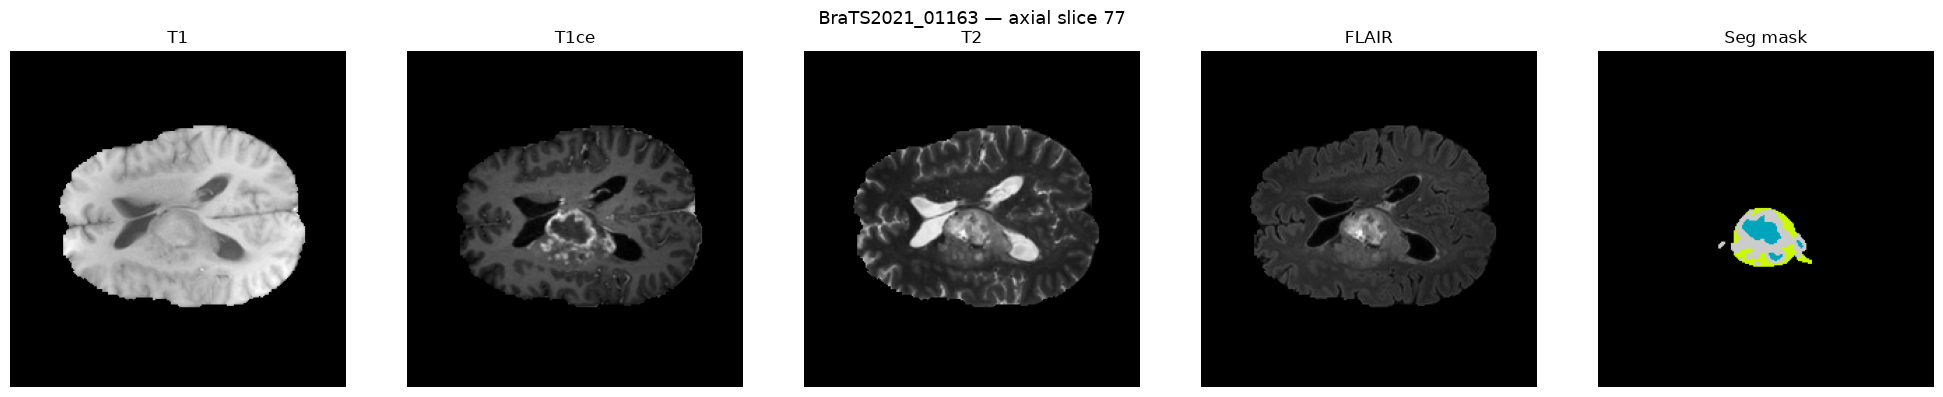

Image shape : (4, 240, 240, 155)   (4, H, W, D)
Mask shape  : (240, 240, 155)   (H, W, D)
Mask labels : [0 1 2 3]
  0 = background
  1 = Necrotic core (NCR)
  2 = Edema (ED)
  3 = Enhancing tumor (ET)


In [17]:
# Load the first patient and display one axial slice
sample_id, sample_path, _ = patients[0]
data = load_patient(sample_path, sample_id)

if data is not None:
    image_4d = build_image_4d(data)
    seg_3d   = build_seg_mask(data)

    # Pick a middle slice
    mid = image_4d.shape[-1] // 2

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    fig.suptitle(f'{sample_id} — axial slice {mid}', fontsize=13)

    titles = ['T1', 'T1ce', 'T2', 'FLAIR', 'Seg mask']
    cmaps  = ['gray', 'gray', 'gray', 'gray', 'nipy_spectral']

    for i, (title, cmap) in enumerate(zip(titles, cmaps)):
        if i < 4:
            axes[i].imshow(image_4d[i, :, :, mid], cmap=cmap)
        else:
            axes[i].imshow(seg_3d[:, :, mid], cmap=cmap, vmin=0, vmax=3)
        axes[i].set_title(title)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

    print(f'Image shape : {image_4d.shape}   (4, H, W, D)')
    print(f'Mask shape  : {seg_3d.shape}   (H, W, D)')
    print(f'Mask labels : {np.unique(seg_3d)}')
    print(f'  0 = background')
    print(f'  1 = Necrotic core (NCR)')
    print(f'  2 = Edema (ED)')
    print(f'  3 = Enhancing tumor (ET)')

In [18]:
# ── Cell 8 (FIXED) — Process and save per patient ──────────────────────────
import os, csv
import numpy as np
import cv2
from tqdm.notebook import tqdm

os.makedirs(RAW_IMG_DIR, exist_ok=True)
os.makedirs(RAW_SEG_DIR, exist_ok=True)
os.makedirs(SLC_IMG_DIR, exist_ok=True)
os.makedirs(SLC_SEG_DIR, exist_ok=True)

index_rows = [['patient_id', 'source', 'num_slices', 'status']]
failed = []

for patient_id, patient_path, source in tqdm(patients, desc='Preprocessing'):

    # Load NIfTI files
    data = load_patient(patient_path, patient_id)
    if data is None:
        index_rows.append([patient_id, source, 0, 'MISSING_FILES'])
        failed.append(patient_id)
        continue

    # Build 3D arrays
    image_4d = build_image_4d(data)
    seg_3d   = build_seg_mask(data)

    # Save raw 3D volumes
    np.savez_compressed(
        os.path.join(RAW_IMG_DIR, f'{patient_id}.npz'), image=image_4d
    )
    np.savez_compressed(
        os.path.join(RAW_SEG_DIR, f'{patient_id}.npz'), mask=seg_3d
    )

    # Extract 2D slices
    img_slices, seg_slices = extract_2d_slices(image_4d, seg_3d)

    # ── Save count BEFORE deleting ──
    n_slices = len(img_slices)

    if img_slices:
        X_pat = np.stack(img_slices, axis=0)  # (n_slices, 4, 256, 256)
        Y_pat = np.stack(seg_slices, axis=0)  # (n_slices, 256, 256)

        np.savez_compressed(
            os.path.join(SLC_IMG_DIR, f'{patient_id}_slices.npz'), images=X_pat
        )
        np.savez_compressed(
            os.path.join(SLC_SEG_DIR, f'{patient_id}_slices.npz'), masks=Y_pat
        )

        # Free memory — use n_slices from now on, not img_slices
        del image_4d, seg_3d, img_slices, seg_slices, X_pat, Y_pat

    index_rows.append([patient_id, source, n_slices, 'OK'])

# Save index
index_path = os.path.join(SAVE_DIR, 'patient_index.csv')
with open(index_path, 'w', newline='') as f:
    csv.writer(f).writerows(index_rows)

print(f'Done. {len(patients) - len(failed)}/{len(patients)} patients processed')
print(f'Index saved → {index_path}')
if failed:
    print(f'Failed: {failed[:5]}')

Preprocessing:   0%|          | 0/1251 [00:00<?, ?it/s]

Done. 1251/1251 patients processed
Index saved → C:\Users\FatmaH\dataset\Preprocessing-fatma\patient_index.csv


In [19]:
index_path = os.path.join(SAVE_DIR, 'patient_index.csv')
with open(index_path, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerows(index_rows)

print(f'Patient index saved → {index_path}')

# Quick summary
ok_rows = [r for r in index_rows[1:] if r[-1] == 'OK']
total_slices = sum(int(r[2]) for r in ok_rows)
print(f'Patients OK        : {len(ok_rows)}')
print(f'Total slices saved : {total_slices}')

Patient index saved → C:\Users\FatmaH\dataset\Preprocessing-fatma\patient_index.csv
Patients OK        : 1251
Total slices saved : 81437


In [20]:
!pip install torch torchvision torchaudio

In [21]:
# ── Cell 9 (NEW) — Dataset class that reads from disk lazily ──────────────

import torch
from torch.utils.data import Dataset, DataLoader

class BraTS2021Dataset(Dataset):
    """
    Reads per-patient .npz slice files on demand.
    Never loads the whole dataset into RAM.
    
    Each item:
        image : (4, 256, 256) float32 tensor  — 4 MRI channels
        mask  : (256, 256)    int64 tensor    — labels 0/1/2/3
    """
    def __init__(self, img_dir, seg_dir):
        self.img_files = sorted([
            os.path.join(img_dir, f)
            for f in os.listdir(img_dir) if f.endswith('_slices.npz')
        ])
        self.seg_files = sorted([
            os.path.join(seg_dir, f)
            for f in os.listdir(seg_dir) if f.endswith('_slices.npz')
        ])
        assert len(self.img_files) == len(self.seg_files), 'Mismatch!'

        # Build a flat index: (file_idx, slice_idx_within_file)
        self.index = []
        for i, f in enumerate(self.img_files):
            n = np.load(f)['images'].shape[0]
            for j in range(n):
                self.index.append((i, j))

        print(f'Dataset ready: {len(self.index)} slices from {len(self.img_files)} patients')

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        file_idx, slice_idx = self.index[idx]
        images = np.load(self.img_files[file_idx])['images'][slice_idx]  # (4,256,256)
        masks  = np.load(self.seg_files[file_idx])['masks'][slice_idx]   # (256,256)
        return (
            torch.from_numpy(images).float(),
            torch.from_numpy(masks).long()
        )


# Test it
dataset = BraTS2021Dataset(SLC_IMG_DIR, SLC_SEG_DIR)
loader  = DataLoader(dataset, batch_size=4, shuffle=True, num_workers=0)

# Check one batch
imgs, masks = next(iter(loader))
print(f'Batch images shape : {imgs.shape}')   # (4, 4, 256, 256)
print(f'Batch masks shape  : {masks.shape}')  # (4, 256, 256)
print(f'Image value range  : [{imgs.min():.2f}, {imgs.max():.2f}]')
print(f'Mask unique labels : {masks.unique().tolist()}')

Dataset ready: 81437 slices from 1251 patients
Batch images shape : torch.Size([4, 4, 256, 256])
Batch masks shape  : torch.Size([4, 256, 256])
Image value range  : [-0.14, 0.98]
Mask unique labels : [0, 1, 2, 3, 4, 255]


Patient files found: 1251
Patient     : BraTS2021_01290
Slices      : 77
Image shape : (77, 4, 256, 256)
Mask shape  : (77, 256, 256)
Mask labels : [0, 1, 2, 3, 4, 255]


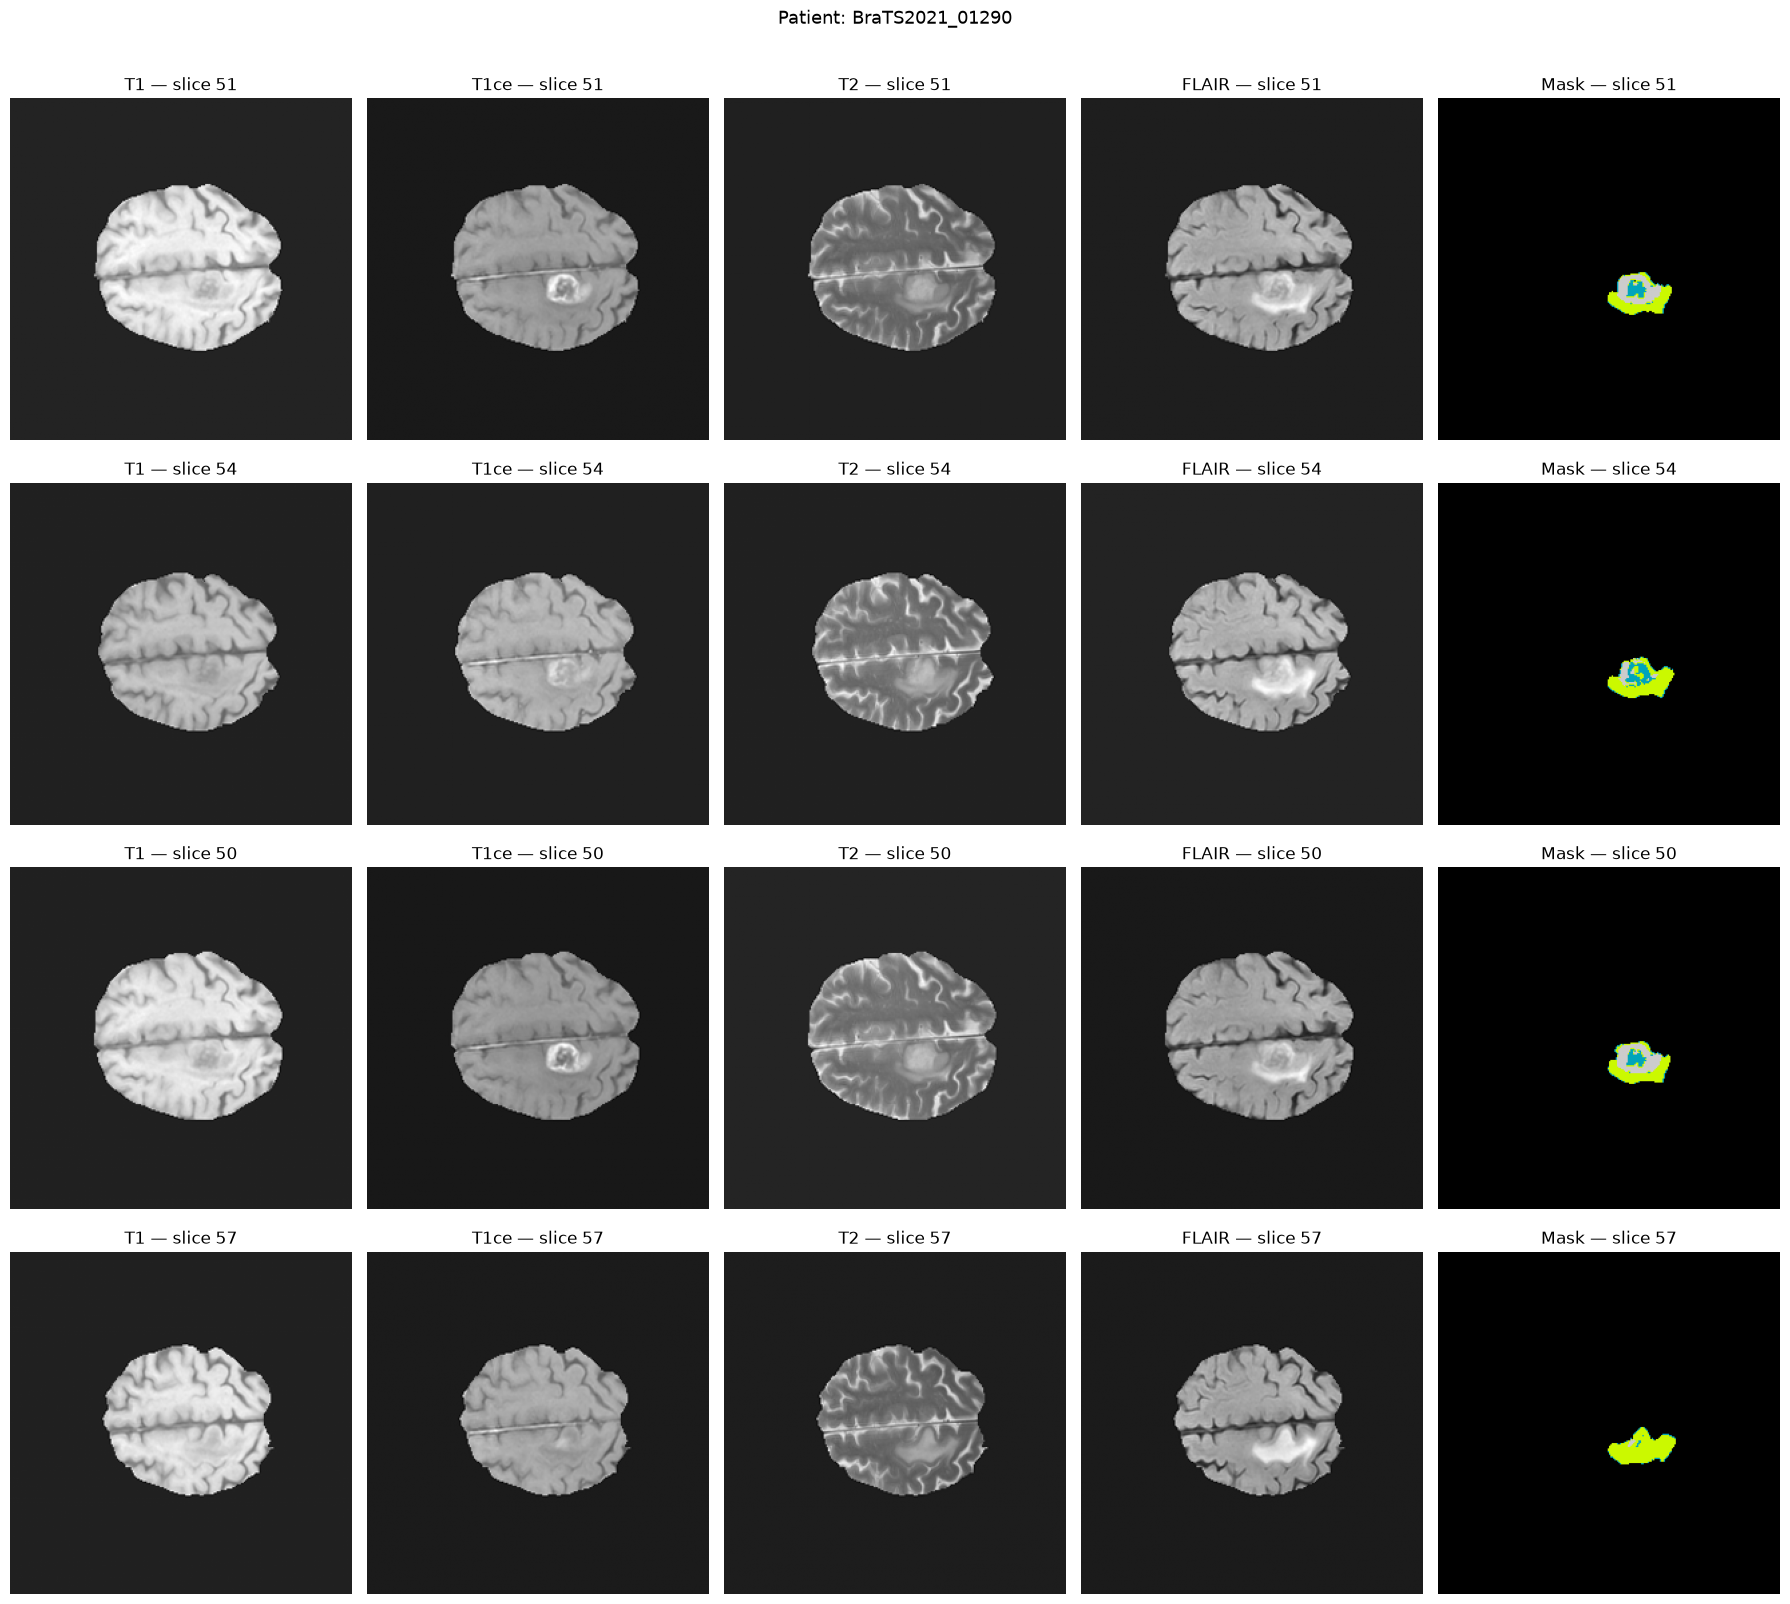

Verification complete!


In [22]:
import random
import matplotlib.pyplot as plt
import numpy as np
import os

# ── Pick a random patient npz file and plot slices from it ──────────────────

patient_files = sorted([
    f for f in os.listdir(SLC_IMG_DIR) if f.endswith('_slices.npz')
])

print(f'Patient files found: {len(patient_files)}')

# Pick one random patient
random_patient = random.choice(patient_files)
patient_id = random_patient.replace('_slices.npz', '')

X_pat = np.load(os.path.join(SLC_IMG_DIR, random_patient))['images']  # (n, 4, 256, 256)
Y_pat = np.load(os.path.join(SLC_SEG_DIR, random_patient))['masks']   # (n, 256, 256)

print(f'Patient     : {patient_id}')
print(f'Slices      : {X_pat.shape[0]}')
print(f'Image shape : {X_pat.shape}')
print(f'Mask shape  : {Y_pat.shape}')
print(f'Mask labels : {np.unique(Y_pat).tolist()}')

# Pick 4 random slices from this patient
idxs = random.sample(range(len(X_pat)), min(4, len(X_pat)))

fig, axes = plt.subplots(len(idxs), 5, figsize=(18, 4 * len(idxs)))
if len(idxs) == 1:
    axes = [axes]  # ensure 2D indexing works for single row

for row, idx in enumerate(idxs):
    for col, (title, cmap) in enumerate(zip(
        ['T1', 'T1ce', 'T2', 'FLAIR', 'Mask'],
        ['gray', 'gray', 'gray', 'gray', 'nipy_spectral']
    )):
        if col < 4:
            axes[row][col].imshow(X_pat[idx, col], cmap=cmap)
        else:
            axes[row][col].imshow(Y_pat[idx], cmap=cmap, vmin=0, vmax=3)
        axes[row][col].set_title(f'{title} — slice {idx}')
        axes[row][col].axis('off')

plt.suptitle(f'Patient: {patient_id}', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()
print('Verification complete!')

Total patients: 1251
Patient     : BraTS2021_01593
Image shape : (4, 240, 240, 155)
Mask shape  : (240, 240, 155)
Mask labels : [0, 1, 2, 3]
Tumor center: x=87  y=122  z=86


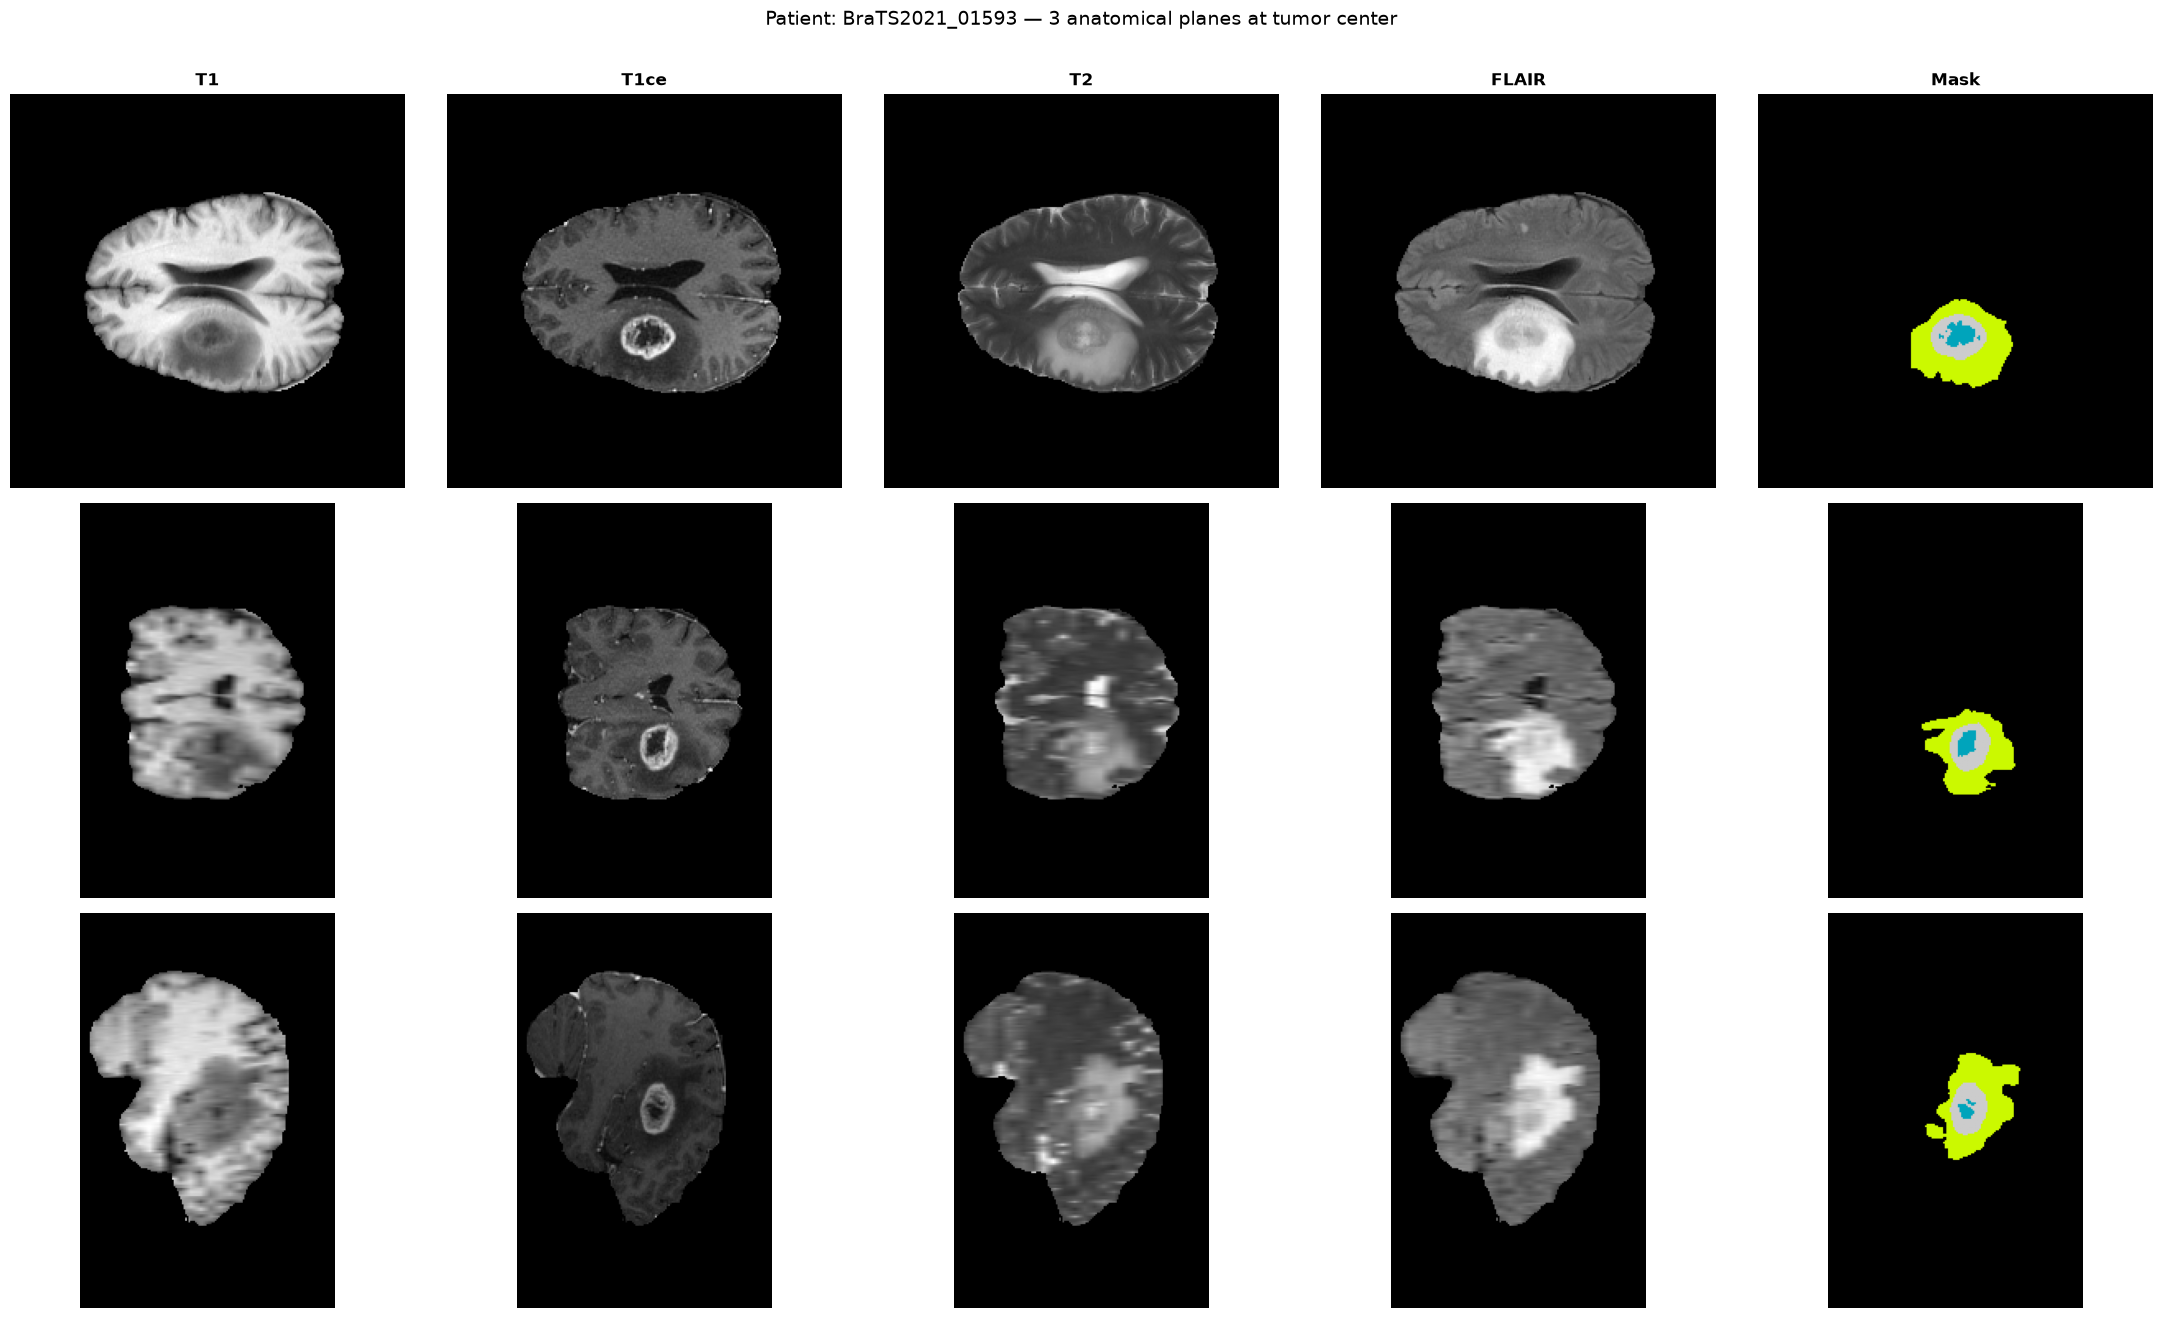

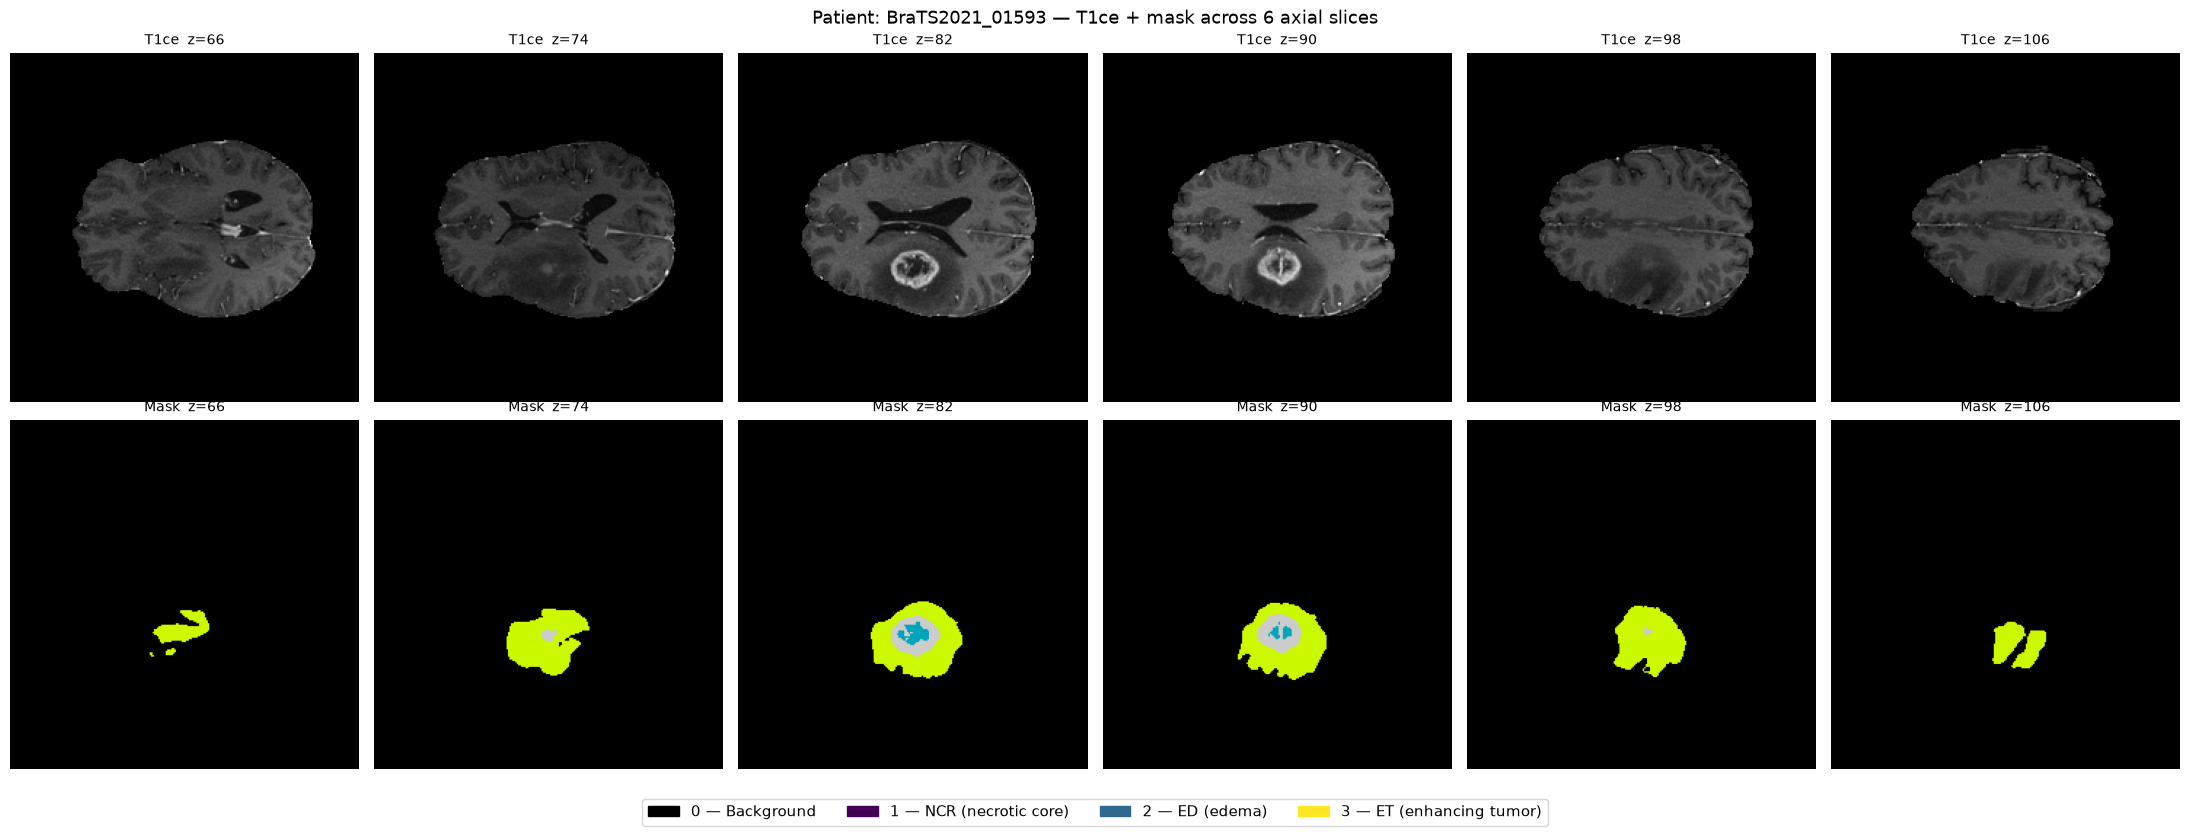

Done!


In [24]:
import random
import matplotlib.pyplot as plt
import numpy as np
import os

# ── Add these 3 lines to define what was missing ─────────────────────────────
RAW_IMG_DIR = r"C:\Users\FatmaH\dataset\Preprocessing-fatma\images_raw"
RAW_SEG_DIR = r"C:\Users\FatmaH\dataset\Preprocessing-fatma\masks_raw"

all_patients = sorted([
    f.replace('.npz', '')
    for f in os.listdir(RAW_IMG_DIR) if f.endswith('.npz')
])
print(f'Total patients: {len(all_patients)}')

# ── Rest of the cell stays exactly the same ───────────────────────────────────
sample_pid = random.choice(all_patients)

image = np.load(os.path.join(RAW_IMG_DIR, f'{sample_pid}.npz'))['image']
mask  = np.load(os.path.join(RAW_SEG_DIR, f'{sample_pid}.npz'))['mask']

mask = mask.copy()
mask[mask == 4] = 3

print(f'Patient     : {sample_pid}')
print(f'Image shape : {image.shape}')
print(f'Mask shape  : {mask.shape}')
print(f'Mask labels : {np.unique(mask).tolist()}')

tumor_voxels = np.argwhere(mask > 0)
center = tumor_voxels.mean(axis=0).astype(int)
cx, cy, cz = center
print(f'Tumor center: x={cx}  y={cy}  z={cz}')

planes     = ['Axial (z)', 'Coronal (y)', 'Sagittal (x)']
modalities = ['T1', 'T1ce', 'T2', 'FLAIR', 'Mask']

fig, axes = plt.subplots(3, 5, figsize=(22, 13))
fig.suptitle(f'Patient: {sample_pid} — 3 anatomical planes at tumor center',
             fontsize=14, y=1.01)

for row in range(3):
    for col in range(5):
        ax = axes[row][col]
        if col < 4:
            if row == 0:
                img = image[col, :, :, cz]
            elif row == 1:
                img = image[col, :, cy, :]
            else:
                img = image[col, cx, :, :]
            ax.imshow(img, cmap='gray', origin='lower')
        else:
            if row == 0:
                seg = mask[:, :, cz]
            elif row == 1:
                seg = mask[:, cy, :]
            else:
                seg = mask[cx, :, :]
            ax.imshow(seg, cmap='nipy_spectral', vmin=0, vmax=3, origin='lower')
        if row == 0:
            ax.set_title(modalities[col], fontsize=12, fontweight='bold')
        ax.set_ylabel(planes[row] if col == 0 else '', fontsize=10)
        ax.axis('off')

plt.tight_layout()
plt.savefig('3d_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

n_slices  = 6
z_indices = np.linspace(max(0, cz-20), min(mask.shape[2]-1, cz+20),
                        n_slices, dtype=int)

fig2, axes2 = plt.subplots(2, n_slices, figsize=(22, 8))
fig2.suptitle(f'Patient: {sample_pid} — T1ce + mask across {n_slices} axial slices',
              fontsize=13)

for i, z in enumerate(z_indices):
    axes2[0][i].imshow(image[1, :, :, z], cmap='gray', origin='lower')
    axes2[0][i].set_title(f'T1ce  z={z}', fontsize=10)
    axes2[0][i].axis('off')
    axes2[1][i].imshow(mask[:, :, z], cmap='nipy_spectral', vmin=0, vmax=3, origin='lower')
    axes2[1][i].set_title(f'Mask  z={z}', fontsize=10)
    axes2[1][i].axis('off')

from matplotlib.patches import Patch
legend = [
    Patch(color='black',   label='0 — Background'),
    Patch(color='#440154', label='1 — NCR (necrotic core)'),
    Patch(color='#31688e', label='2 — ED (edema)'),
    Patch(color='#fde725', label='3 — ET (enhancing tumor)'),
]
fig2.legend(handles=legend, loc='lower center', ncol=4,
            fontsize=11, frameon=True, bbox_to_anchor=(0.5, -0.05))

plt.tight_layout()
plt.savefig('axial_scroll.png', dpi=150, bbox_inches='tight')
plt.show()
print('Done!')

In [25]:
import os
import random

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split


# ============================================================
# Device
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device : {device}")

if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")


# ============================================================
# Dataset
# ============================================================

class BraTS3DDataset(Dataset):

    def __init__(
        self,
        patient_ids,
        img_dir,
        seg_dir,
        patch_size=128,
        patches_per_patient=4,
        augment=False
    ):

        self.img_dir = img_dir
        self.seg_dir = seg_dir
        self.patch_size = patch_size
        self.augment = augment
        self.index = []

        for pid in patient_ids:

            img_path = os.path.join(img_dir, f"{pid}.npz")
            seg_path = os.path.join(seg_dir, f"{pid}.npz")

            if os.path.exists(img_path) and os.path.exists(seg_path):

                for _ in range(patches_per_patient):
                    self.index.append(pid)

            else:
                print(f"WARNING: Missing {pid}")

        print(
            f"Dataset ready: {len(self.index)} patches "
            f"from {len(patient_ids)} patients"
        )

    def __len__(self):
        return len(self.index)

    # --------------------------------------------------------
    # Generic crop
    # --------------------------------------------------------

    def _crop(self, image, mask, center):

        P = self.patch_size
        _, H, W, D = image.shape

        cx, cy, cz = center

        x = int(np.clip(cx - P // 2, 0, max(0, H - P)))
        y = int(np.clip(cy - P // 2, 0, max(0, W - P)))
        z = int(np.clip(cz - P // 2, 0, max(0, D - P)))

        return (
            image[:, x:x+P, y:y+P, z:z+P],
            mask[x:x+P, y:y+P, z:z+P]
        )

    # --------------------------------------------------------
    # Random tumor-centered crop (training)
    # --------------------------------------------------------

    def _training_crop(
        self,
        image,
        mask,
        min_fg_voxels=200,
        max_attempts=5
    ):
       
        _, H, W, D = image.shape

        tumor = np.argwhere(mask > 0)

        for attempt in range(max_attempts):

            if len(tumor) and random.random() < 0.85:

                center = tumor[random.randint(0, len(tumor) - 1)]

            else:

                center = (
                    random.randint(0, H-1),
                    random.randint(0, W-1),
                    random.randint(0, D-1)
                )

            img_patch, mask_patch = self._crop(image, mask, center)

            if len(tumor) == 0 or np.sum(mask_patch > 0) >= min_fg_voxels:
                return img_patch, mask_patch

        # Fallback: guaranteed tumor-centered crop
        if len(tumor):
            center = tuple(np.mean(tumor, axis=0).astype(int))
        else:
            center = (H // 2, W // 2, D // 2)

        return self._crop(image, mask, center)

    # --------------------------------------------------------
    # Fixed tumor-centered crop (validation)
    # --------------------------------------------------------

    def _validation_crop(self, image, mask):

        _, H, W, D = image.shape

        tumor = np.argwhere(mask > 0)

        if len(tumor):

            center = tuple(
                np.mean(tumor, axis=0).astype(int)
            )

        else:

            center = (
                H // 2,
                W // 2,
                D // 2
            )

        return self._crop(image, mask, center)

    # --------------------------------------------------------
    # Augmentation
    # --------------------------------------------------------

    def _augment(self, image, mask):

        for axis in (1, 2, 3):

            if random.random() < 0.5:

                image = np.flip(image, axis).copy()
                mask = np.flip(mask, axis-1).copy()

        
        if random.random() < 0.3:
            gamma = np.random.uniform(0.7, 1.5)
            img_min = image.min()
            img_range = image.max() - img_min + 1e-8
            image = ((image - img_min) / img_range) ** gamma * img_range + img_min
            image = image.astype(np.float32)

        # Random per-channel intensity shift/scale
        if random.random() < 0.5:
            shift = np.random.uniform(-0.1, 0.1, size=(image.shape[0], 1, 1, 1)).astype(np.float32)
            scale = np.random.uniform(0.9, 1.1, size=(image.shape[0], 1, 1, 1)).astype(np.float32)
            image = (image * scale + shift).astype(np.float32)

        return image, mask

    # --------------------------------------------------------
    # Get item
    # --------------------------------------------------------

    def __getitem__(self, idx):

        pid = self.index[idx]

        image = np.load(
            os.path.join(self.img_dir, f"{pid}.npz")
        )["image"]

        mask = np.load(
            os.path.join(self.seg_dir, f"{pid}.npz")
        )["mask"]

        # BraTS labels
        mask = mask.copy()
        mask[mask == 4] = 3

        if self.augment:

            image, mask = self._training_crop(image, mask)

            image, mask = self._augment(image, mask)

        else:

            image, mask = self._validation_crop(image, mask)

        return (
            torch.from_numpy(image).float(),
            torch.from_numpy(mask.astype(np.int64)).long()
        )


# ============================================================
# Build datasets
# ============================================================

all_patients = sorted(
    f.replace(".npz", "")
    for f in os.listdir(RAW_IMG_DIR)
    if f.endswith(".npz")
)

print(f"\nTotal patients: {len(all_patients)}")

train_patients, val_patients = train_test_split(
    all_patients,
    test_size=0.2,
    random_state=42
)

print(f"Train patients      : {len(train_patients)}")
print(f"Validation patients : {len(val_patients)}")


PATCH_SIZE = 128


train_dataset = BraTS3DDataset(
    train_patients,
    RAW_IMG_DIR,
    RAW_SEG_DIR,
    patch_size=PATCH_SIZE,
    patches_per_patient=4,
    augment=True
)

val_dataset = BraTS3DDataset(
    val_patients,
    RAW_IMG_DIR,
    RAW_SEG_DIR,
    patch_size=PATCH_SIZE,
    patches_per_patient=1,
    augment=False
)


train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


imgs, masks = next(iter(train_loader))

print("\nVerification")
print("----------------------------")
print("Image shape :", imgs.shape)
print("Mask shape  :", masks.shape)
print("Labels      :", masks.unique().tolist())

Device : cuda
GPU    : NVIDIA GeForce RTX 5090 Laptop GPU

Total patients: 1251
Train patients      : 1000
Validation patients : 251
Dataset ready: 4000 patches from 1000 patients
Dataset ready: 251 patches from 251 patients

Verification
----------------------------
Image shape : torch.Size([1, 4, 128, 128, 128])
Mask shape  : torch.Size([1, 128, 128, 128])
Labels      : [0, 1, 2, 3]


In [26]:
# ============================================================
# 3D U-Net
# ============================================================

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.InstanceNorm3d(out_channels),
            nn.LeakyReLU(inplace=True),

            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.InstanceNorm3d(out_channels),
            nn.LeakyReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class ImprovedUNet3D(nn.Module):

    def __init__(
        self,
        in_channels=4,
        out_channels=4,
        base_filters=16,
        dropout=0.3
    ):

        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, base_filters)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv(base_filters, base_filters * 2)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = DoubleConv(base_filters * 2, base_filters * 4)
        self.pool3 = nn.MaxPool3d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(
            base_filters * 4,
            base_filters * 8
        )

        self.dropout = nn.Dropout3d(dropout)

        # Decoder
        self.up3 = nn.ConvTranspose3d(
            base_filters * 8,
            base_filters * 4,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            base_filters * 8,
            base_filters * 4
        )

        self.up2 = nn.ConvTranspose3d(
            base_filters * 4,
            base_filters * 2,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            base_filters * 4,
            base_filters * 2
        )

        self.up1 = nn.ConvTranspose3d(
            base_filters * 2,
            base_filters,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            base_filters * 2,
            base_filters
        )

        self.final_conv = nn.Conv3d(
            base_filters,
            out_channels,
            kernel_size=1
        )

        # Deep supervision heads — lightweight 1x1x1 convs reading
        # straight off the decoder feature maps at 1/2 and 1/4
        # resolution, before the final upsampling stages.
        self.aux_head2 = nn.Conv3d(base_filters * 2, out_channels, kernel_size=1)  # from d2, 1/2 res
        self.aux_head3 = nn.Conv3d(base_filters * 4, out_channels, kernel_size=1)  # from d3, 1/4 res

        self._initialize_weights()

    def _initialize_weights(self):

        for m in self.modules():

            if isinstance(m, nn.Conv3d):

                nn.init.kaiming_normal_(
                    m.weight,
                    nonlinearity="leaky_relu"
                )

                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

            elif isinstance(m, nn.InstanceNorm3d):

                if m.weight is not None:
                    nn.init.constant_(m.weight, 1)

                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

    @staticmethod
    def _pad(x, ref):

        diffZ = ref.size(2) - x.size(2)
        diffY = ref.size(3) - x.size(3)
        diffX = ref.size(4) - x.size(4)

        if diffZ or diffY or diffX:

            x = F.pad(
                x,
                [
                    diffX // 2,
                    diffX - diffX // 2,

                    diffY // 2,
                    diffY - diffY // 2,

                    diffZ // 2,
                    diffZ - diffZ // 2,
                ]
            )

        return x

    def forward(self, x, deep_supervision=False):

        e1 = self.enc1(x)

        e2 = self.enc2(self.pool1(e1))

        e3 = self.enc3(self.pool2(e2))

        b = self.dropout(
            self.bottleneck(
                self.pool3(e3)
            )
        )

        d3 = self.up3(b)
        d3 = self._pad(d3, e3)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self._pad(d2, e2)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self._pad(d1, e1)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        main_out = self.final_conv(d1)

        if deep_supervision and self.training:
            aux2 = self.aux_head2(d2)   # 1/2 resolution logits
            aux3 = self.aux_head3(d3)   # 1/4 resolution logits
            return main_out, aux2, aux3

        return main_out


# ============================================================
# Model
# ============================================================

model = ImprovedUNet3D(
    in_channels=4,
    out_channels=4,
    base_filters=16
).to(device)

model.eval()

with torch.no_grad():

    dummy = torch.randn(
        1,
        4,
        PATCH_SIZE,
        PATCH_SIZE,
        PATCH_SIZE
    ).to(device)

    output = model(dummy)

    print(f"\nInput shape  : {dummy.shape}")
    print(f"Output shape : {output.shape}")

del dummy, output

if torch.cuda.is_available():
    torch.cuda.empty_cache()

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"\nTrainable parameters: {total_params:,}")

model.train()


Input shape  : torch.Size([1, 4, 128, 128, 128])
Output shape : torch.Size([1, 4, 128, 128, 128])

Trainable parameters: 1,402,300


ImprovedUNet3D(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv3d(4, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): InstanceNorm3d(16, eps=1e-05, momentum=0.1, affine=False, bias=False, track_running_stats=False)
      (2): LeakyReLU(negative_slope=0.01, inplace=True)
      (3): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (4): InstanceNorm3d(16, eps=1e-05, momentum=0.1, affine=False, bias=False, track_running_stats=False)
      (5): LeakyReLU(negative_slope=0.01, inplace=True)
    )
  )
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): InstanceNorm3d(32, eps=1e-05, momentum=0.1, affine=False, bias=False, track_running_stats=False)
      (2): LeakyReLU(negative_slope=0.01, inplace=True)
      (3): Conv3d(32, 32, kernel_size=(3, 3, 

In [27]:
# ── Debug cell: check what's actually in your saved .npz files ──
import os
import numpy as np

# Load one patient's mask directly and check labels
sample_pid = all_patients[0]
mask_raw = np.load(os.path.join(RAW_SEG_DIR, f'{sample_pid}.npz'))['mask']

print(f"Patient         : {sample_pid}")
print(f"Mask shape      : {mask_raw.shape}")
print(f"Unique labels   : {np.unique(mask_raw)}")
print(f"Non-zero voxels : {np.sum(mask_raw > 0)}")
print(f"Label 4 count   : {np.sum(mask_raw == 4)}")
print(f"Label 3 count   : {np.sum(mask_raw == 3)}")
print(f"Label 2 count   : {np.sum(mask_raw == 2)}")
print(f"Label 1 count   : {np.sum(mask_raw == 1)}")

Patient         : BraTS2021_00000
Mask shape      : (240, 240, 155)
Unique labels   : [0 1 2 3]
Non-zero voxels : 57305
Label 4 count   : 0
Label 3 count   : 32731
Label 2 count   : 12836
Label 1 count   : 11738


In [28]:
# ── Debug: trace exactly what happens inside __getitem__ ──
import numpy as np
import random

sample_pid = all_patients[0]

# Step 1: load raw
image = np.load(os.path.join(RAW_IMG_DIR, f'{sample_pid}.npz'))['image']
mask  = np.load(os.path.join(RAW_SEG_DIR, f'{sample_pid}.npz'))['mask']
print(f"1. After load     — labels: {np.unique(mask)}  dtype: {mask.dtype}")

# Step 2: remap
mask = mask.copy()
mask[mask == 4] = 3
print(f"2. After remap    — labels: {np.unique(mask)}  non-zero: {np.sum(mask > 0)}")

# Step 3: find tumor voxels
tumor_voxels = np.argwhere(mask > 0)
print(f"3. Tumor voxels   — count: {len(tumor_voxels)}")

# Step 4: pick center and crop
P = 128
_, H, W, D = image.shape
print(f"4. Volume shape   — H:{H}  W:{W}  D:{D}  patch:{P}")

if len(tumor_voxels) > 0:
    center = tumor_voxels[random.randint(0, len(tumor_voxels) - 1)]
    cx, cy, cz = center
    x = int(np.clip(cx - P // 2, 0, max(0, H - P)))
    y = int(np.clip(cy - P // 2, 0, max(0, W - P)))
    z = int(np.clip(cz - P // 2, 0, max(0, D - P)))
    print(f"5. Crop origin    — x:{x}  y:{y}  z:{z}")
    print(f"   Tumor center   — cx:{cx}  cy:{cy}  cz:{cz}")

    mask_patch = mask[x:x+P, y:y+P, z:z+P]
    print(f"6. Patch labels   — {np.unique(mask_patch)}")
    print(f"   Non-zero in patch: {np.sum(mask_patch > 0)}")

1. After load     — labels: [0 1 2 3]  dtype: uint8
2. After remap    — labels: [0 1 2 3]  non-zero: 57305
3. Tumor voxels   — count: 57305
4. Volume shape   — H:240  W:240  D:155  patch:128
5. Crop origin    — x:74  y:36  z:1
   Tumor center   — cx:138  cy:100  cz:65
6. Patch labels   — [0 1 2 3]
   Non-zero in patch: 57305


In [29]:
# Check 10 batches — not just the first one
print("Checking 10 batches...")
for i, (imgs, masks) in enumerate(train_loader):
    labels = masks.unique().tolist()
    print(f"  Batch {i+1}: labels = {labels}")
    if i == 9:
        break

Checking 10 batches...
  Batch 1: labels = [0, 1, 2, 3]
  Batch 2: labels = [0, 1, 2, 3]
  Batch 3: labels = [0, 1, 2, 3]
  Batch 4: labels = [0, 1, 2, 3]
  Batch 5: labels = [0, 1, 2, 3]
  Batch 6: labels = [0, 1, 2, 3]
  Batch 7: labels = [0, 2, 3]
  Batch 8: labels = [0, 1, 2, 3]
  Batch 9: labels = [0, 1, 2, 3]
  Batch 10: labels = [0, 1, 2, 3]


In [30]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device : {device}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")


torch.cuda.reset_peak_memory_stats()

try:
    model = ImprovedUNet3D(in_channels=4, out_channels=4, base_filters=32).to(device)
    print(f"Model device check: {next(model.parameters()).device}")

    dummy = torch.randn(2, 4, 128, 128, 128, device=device)  # batch_size=2
    out   = model(dummy)
    loss  = out.sum()
    loss.backward()

    torch.cuda.synchronize()
    peak_gb = torch.cuda.max_memory_allocated() / 1e9
    print(f"Patch 128, batch 2, base_filters=32 fits in memory ✓")
    print(f"Peak memory used: {peak_gb:.2f} GB / 24 GB available")
    del dummy, out, loss

except RuntimeError as e:
    if "out of memory" in str(e):
        print("OOM at batch 2 — drop to batch 1 or base_filters=24")
    else:
        raise e

torch.cuda.empty_cache()

Device : cuda
GPU    : NVIDIA GeForce RTX 5090 Laptop GPU
Model device check: cuda:0
Patch 128, batch 2, base_filters=32 fits in memory ✓
Peak memory used: 9.66 GB / 24 GB available


In [31]:

PATCH_SIZE = 128

print(f"\nUsing patch size: {PATCH_SIZE}")

# ============================================================
# Datasets
# ============================================================

train_dataset = BraTS3DDataset(
    train_patients,
    RAW_IMG_DIR,
    RAW_SEG_DIR,
    patch_size=PATCH_SIZE,
    patches_per_patient=4,
    augment=True
)

val_dataset = BraTS3DDataset(
    val_patients,
    RAW_IMG_DIR,
    RAW_SEG_DIR,
    patch_size=PATCH_SIZE,
    patches_per_patient=1,      # Deterministic validation
    augment=False
)

# ============================================================
# DataLoaders
# ============================================================

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# ============================================================
# Model
# ============================================================

model = ImprovedUNet3D(
    in_channels=4,
    out_channels=4,
    base_filters=32
).to(device)

print(f"Model device check: {next(model.parameters()).device}")

# ============================================================
# Shape check
# ============================================================

model.eval()

with torch.no_grad():

    dummy = torch.randn(
        1,
        4,
        PATCH_SIZE,
        PATCH_SIZE,
        PATCH_SIZE,
        device=device
    )

    output = model(dummy)

    print(f"Input shape : {dummy.shape}")
    print(f"Output shape: {output.shape}")

del dummy, output

if torch.cuda.is_available():
    torch.cuda.empty_cache()

model.train()

print("\n✓ Model and datasets are ready for training.")


Using patch size: 128
Dataset ready: 4000 patches from 1000 patients
Dataset ready: 251 patches from 251 patients
Model device check: cuda:0
Input shape : torch.Size([1, 4, 128, 128, 128])
Output shape: torch.Size([1, 4, 128, 128, 128])

✓ Model and datasets are ready for training.



Starting Training

Epoch [1/100]


Training:   0%|          | 0/2000 [00:00<?, ?it/s]

Validation:   0%|          | 0/126 [00:00<?, ?it/s]

Train | Loss: 0.3145 | Dice: 0.7152
Val   | Loss: 0.1691 | Dice: 0.8124 | LR: 0.000200
✓ Best model saved (Dice = 0.8124)

Epoch [2/100]


Training:   0%|          | 0/2000 [00:00<?, ?it/s]

Validation:   0%|          | 0/126 [00:00<?, ?it/s]

... (132 outputs left out)

Train | Loss: 0.0822 | Dice: 0.9023
Val   | Loss: 0.1006 | Dice: 0.8756 | LR: 0.000004

Epoch [47/100]


Training:   0%|          | 0/2000 [00:00<?, ?it/s]

Validation:   0%|          | 0/126 [00:00<?, ?it/s]

Train | Loss: 0.0812 | Dice: 0.9038
Val   | Loss: 0.1004 | Dice: 0.8759 | LR: 0.000003

Early stopping triggered after 47 epochs.

Training Finished
Best Validation Dice: 0.8771


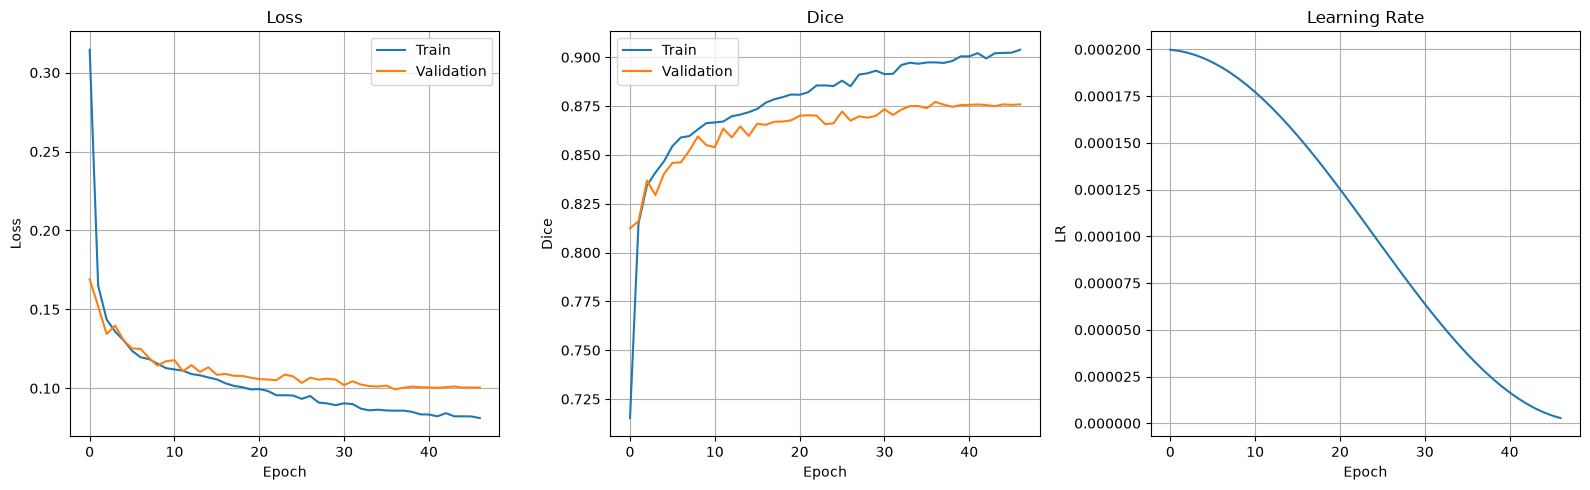

In [32]:
from tqdm.auto import tqdm

# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):
    def __init__(self, num_classes=4, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        

        probs = F.softmax(logits, dim=1)

        total_loss = 0.0
        n_present = 0

        for c in range(1, self.num_classes):

            true = (targets == c).float().reshape(-1)

            if true.sum() == 0:
                continue

            pred = probs[:, c].reshape(-1)

            intersection = (pred * true).sum()

            dice = (
                2.0 * intersection + self.smooth
            ) / (
                pred.sum() + true.sum() + self.smooth
            )

            total_loss += 1.0 - dice
            n_present += 1

        if n_present == 0:
            return torch.tensor(0.0, device=logits.device, requires_grad=True)

        return total_loss / n_present


# ============================================================
# Combined Dice + Cross Entropy
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(self,
                 w_dice=0.7,
                 w_ce=0.3):

        super().__init__()

        self.dice = DiceLoss(num_classes=4)
        self.ce = nn.CrossEntropyLoss()

        self.w_dice = w_dice
        self.w_ce = w_ce

    def forward(self, logits, targets):

        ce_loss = self.ce(logits, targets)
        dice_loss = self.dice(logits, targets)

        return (
            self.w_ce * ce_loss +
            self.w_dice * dice_loss
        )


# ============================================================
# Deep Supervision Wrapper
# ============================================================


class DeepSupervisionLoss(nn.Module):

    def __init__(self, base_criterion, weights=(1.0, 0.5, 0.25)):
        super().__init__()
        self.base = base_criterion
        w = np.array(weights, dtype=np.float32)
        self.weights = (w / w.sum()).tolist()

    def forward(self, outputs, targets):

        if not isinstance(outputs, (tuple, list)):
            return self.base(outputs, targets)

        total = 0.0

        for out, w in zip(outputs, self.weights):

            if out.shape[2:] != targets.shape[1:]:
                t = F.interpolate(
                    targets.unsqueeze(1).float(),
                    size=out.shape[2:],
                    mode='nearest'
                ).squeeze(1).long()
            else:
                t = targets

            total = total + w * self.base(out, t)

        return total


# ============================================================
# Mean Dice Metric
# ============================================================

def dice_mean(
        logits,
        targets,
        num_classes=4,
        smooth=1e-6):

    preds = logits.argmax(dim=1)

    scores = []

    for c in range(1, num_classes):

        pred = (preds == c).float().reshape(-1)
        true = (targets == c).float().reshape(-1)

        # Ignore classes absent in GT
        if true.sum() == 0:
            continue

        intersection = (pred * true).sum()

        dice = (
            2 * intersection + smooth
        ) / (
            pred.sum() + true.sum() + smooth
        )

        scores.append(dice.item())

    if len(scores) == 0:
        return 1.0

    return float(np.mean(scores))


# ============================================================
# Training Configuration
# ============================================================

criterion = DeepSupervisionLoss(
    CombinedLoss(w_dice=0.7, w_ce=0.3),
    weights=(1.0, 0.5, 0.25)   # main, 1/2-res aux, 1/4-res aux
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-5
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=50,
    eta_min=1e-6
)

use_amp = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)


# ============================================================
# Train One Epoch
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device,
    scaler
):

    model.train()

    epoch_loss = 0.0
    epoch_dice = 0.0

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for imgs, masks in progress:

        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
                "cuda",
                enabled=use_amp):

            outputs = model(imgs, deep_supervision=True)

            loss = criterion(
                outputs,
                masks
            )

        if use_amp:

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)

            scaler.update()

        else:

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

        main_out = outputs[0] if isinstance(outputs, (tuple, list)) else outputs

        batch_dice = dice_mean(
            main_out.detach(),
            masks
        )

        epoch_loss += loss.item()
        epoch_dice += batch_dice

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            dice=f"{batch_dice:.4f}"
        )

    epoch_loss /= len(loader)
    epoch_dice /= len(loader)

    return epoch_loss, epoch_dice


# ============================================================
# Validation
# ============================================================

def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    epoch_loss = 0.0
    epoch_dice = 0.0

    progress = tqdm(
        loader,
        desc="Validation",
        leave=False
    )

    with torch.no_grad():

        for imgs, masks in progress:

            imgs = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.amp.autocast(
                    "cuda",
                    enabled=use_amp):

                outputs = model(imgs)

                loss = criterion(
                    outputs,
                    masks
                )

            batch_dice = dice_mean(
                outputs,
                masks
            )

            epoch_loss += loss.item()
            epoch_dice += batch_dice

            progress.set_postfix(
                loss=f"{loss.item():.4f}",
                dice=f"{batch_dice:.4f}"
            )

    epoch_loss /= len(loader)
    epoch_dice /= len(loader)

    return epoch_loss, epoch_dice
# ============================================================
# Early Stopping
# ============================================================

class EarlyStopping:

    def __init__(
        self,
        patience=10,
        min_delta=0.001
    ):

        self.patience = patience
        self.min_delta = min_delta

        self.counter = 0
        self.best_loss = None

        self.early_stop = False

    def __call__(self, val_loss):

        if self.best_loss is None:

            self.best_loss = val_loss
            return

        if val_loss < self.best_loss - self.min_delta:

            self.best_loss = val_loss
            self.counter = 0

        else:

            self.counter += 1

            if self.counter >= self.patience:

                self.early_stop = True


# ============================================================
# Training
# ============================================================

NUM_EPOCHS = 100

best_val_dice = 0.0

early_stopping = EarlyStopping(
    patience=10,
    min_delta=0.001
)

train_losses = []
val_losses = []

train_dices = []
val_dices = []

learning_rates = []


print("\n==============================")
print("Starting Training")
print("==============================")

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")

    train_loss, train_dice = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device,
        scaler
    )

    val_loss, val_dice = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_dices.append(train_dice)
    val_dices.append(val_dice)

    learning_rates.append(current_lr)

    print(
        f"Train | Loss: {train_loss:.4f} | Dice: {train_dice:.4f}"
    )

    print(
        f"Val   | Loss: {val_loss:.4f} | Dice: {val_dice:.4f} | LR: {current_lr:.6f}"
    )

    ###########################################################
    # Save Best Model
    ###########################################################

    if val_dice > best_val_dice:

        best_val_dice = val_dice

        torch.save(

            {

                "epoch": epoch + 1,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "best_val_dice":
                    best_val_dice,

                "train_loss":
                    train_loss,

                "val_loss":
                    val_loss

            },

            "best_unet3d_brats2021_p128_bf32_rtx5090.pth"

        )

        print(
            f"✓ Best model saved "
            f"(Dice = {best_val_dice:.4f})"
        )

    ###########################################################
    # Early Stopping
    ###########################################################

    early_stopping(val_loss)

    if early_stopping.early_stop:

        print(
            f"\nEarly stopping triggered "
            f"after {epoch+1} epochs."
        )

        break


print("\n==============================")
print("Training Finished")
print("==============================")

print(
    f"Best Validation Dice: "
    f"{best_val_dice:.4f}"
)


# ============================================================
# Plot Training Curves
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

axes[0].plot(
    train_losses,
    label="Train"
)

axes[0].plot(
    val_losses,
    label="Validation"
)

axes[0].set_title("Loss")

axes[0].set_xlabel("Epoch")

axes[0].set_ylabel("Loss")

axes[0].legend()

axes[0].grid(True)


# ------------------------------------------------------------
# Dice
# ------------------------------------------------------------

axes[1].plot(
    train_dices,
    label="Train"
)

axes[1].plot(
    val_dices,
    label="Validation"
)

axes[1].set_title("Dice")

axes[1].set_xlabel("Epoch")

axes[1].set_ylabel("Dice")

axes[1].legend()

axes[1].grid(True)


# ------------------------------------------------------------
# Learning Rate
# ------------------------------------------------------------

axes[2].plot(
    learning_rates
)

axes[2].set_title("Learning Rate")

axes[2].set_xlabel("Epoch")

axes[2].set_ylabel("LR")

axes[2].grid(True)

plt.tight_layout()

plt.savefig(
    "training_metrics.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Full-Volume Evaluation: Sliding-Window Inference + TTA + Postprocessing

The Dice printed during training (`dice_mean`) is measured on single 128³ patches — useful as
a training signal, but **not** the number to report. It's not comparable to BraTS leaderboard
numbers, which are computed on the *whole* segmented volume.

This section:
1. Runs the trained model over each full validation volume using **overlapping sliding windows**
   with Gaussian-weighted blending at the seams (so a tumor spanning multiple windows doesn't
   get a seam artifact).
2. Applies **test-time augmentation** (flip along each axis, average predictions) at every window.
3. **Postprocesses** the prediction — keeps only the largest connected component per class, to
   remove small spurious false-positive blobs.
4. Reports Dice per BraTS region (WT / TC / ET) over the *entire* volume, which is the real,
   comparable number.

This is slower per-patient than the patch-based validation used during training (each patient
now costs several forward passes, ×4 for TTA), so it's meant to be run **after** training
finishes, not every epoch.

In [33]:
import torch.nn.functional as F
from scipy import ndimage


def gaussian_importance_map(patch_size, sigma_scale=0.125):
    """Gaussian weighting so overlapping window edges blend smoothly
    instead of showing seam artifacts (nnU-Net-style)."""
    coords = np.arange(patch_size) - patch_size // 2
    sigma = patch_size * sigma_scale
    g1d = np.exp(-(coords ** 2) / (2 * sigma ** 2))
    g3d = np.einsum('i,j,k->ijk', g1d, g1d, g1d)
    g3d = g3d / g3d.max()
    return g3d.astype(np.float32)


def get_window_starts(dim_size, patch_size, stride):
    """Overlapping window start positions covering the full axis,
    including a final window flush with the far edge."""
    if dim_size <= patch_size:
        return [0]
    starts = list(range(0, dim_size - patch_size + 1, stride))
    if starts[-1] != dim_size - patch_size:
        starts.append(dim_size - patch_size)
    return starts


@torch.no_grad()
def sliding_window_inference(
    model,
    image,                # (4, H, W, D) torch tensor, already normalized
    patch_size=128,
    overlap=0.5,
    num_classes=4,
    device="cuda",
    use_tta=True
):
    """Returns averaged softmax probabilities, shape (num_classes, H, W, D)."""

    model.eval()

    _, H, W, D = image.shape
    stride = max(int(patch_size * (1 - overlap)), 1)

    weight_np = gaussian_importance_map(patch_size)
    weight = torch.from_numpy(weight_np).to(device)

    prob_sum = torch.zeros((num_classes, H, W, D), device=device)
    weight_sum = torch.zeros((H, W, D), device=device)

    xs = get_window_starts(H, patch_size, stride)
    ys = get_window_starts(W, patch_size, stride)
    zs = get_window_starts(D, patch_size, stride)

    flip_dims_list = [(2,), (3,), (4,)]  # H, W, D axes on a (1,4,P,P,P) tensor

    for x in xs:
        for y in ys:
            for z in zs:

                patch = image[:, x:x+patch_size, y:y+patch_size, z:z+patch_size]
                patch = patch.unsqueeze(0).to(device)

                probs = F.softmax(model(patch), dim=1)[0]

                if use_tta:
                    count = 1
                    for flip_dims in flip_dims_list:
                        flipped = torch.flip(patch, dims=flip_dims)
                        out_f = model(flipped)
                        out_f = torch.flip(out_f, dims=flip_dims)
                        probs = probs + F.softmax(out_f, dim=1)[0]
                        count += 1
                    probs = probs / count

                prob_sum[:, x:x+patch_size, y:y+patch_size, z:z+patch_size] += probs * weight
                weight_sum[x:x+patch_size, y:y+patch_size, z:z+patch_size] += weight

    prob_sum = prob_sum / weight_sum.unsqueeze(0).clamp(min=1e-8)
    return prob_sum


def keep_largest_component(pred_mask, num_classes=4):
    """Per class (excluding background), keep only the largest
    connected component. Removes small spurious false-positive blobs
    that hurt Dice without adding real clinical information."""

    cleaned = np.zeros_like(pred_mask)

    for c in range(1, num_classes):

        binary = (pred_mask == c)

        if binary.sum() == 0:
            continue

        labeled, n_components = ndimage.label(binary)

        if n_components == 0:
            continue

        sizes = ndimage.sum(binary, labeled, range(1, n_components + 1))
        largest_label = np.argmax(sizes) + 1

        cleaned[labeled == largest_label] = c

    return cleaned


def dice_score(a, b):
    a = a.astype(bool)
    b = b.astype(bool)
    if a.sum() == 0 and b.sum() == 0:
        return 1.0
    intersection = np.logical_and(a, b).sum()
    return (2.0 * intersection) / (a.sum() + b.sum() + 1e-8)


def compute_region_dice(pred, gt):
    """BraTS-standard region grouping.
    WT = whole tumor (all labels), TC = tumor core (NCR+ET), ET = enhancing tumor only.
    Assumes labels already remapped so ET=3."""

    return {
        "WT": dice_score(pred > 0, gt > 0),
        "TC": dice_score(np.isin(pred, [1, 3]), np.isin(gt, [1, 3])),
        "ET": dice_score(pred == 3, gt == 3),
    }

print("Sliding-window inference, TTA, and postprocessing utilities ready.")

Sliding-window inference, TTA, and postprocessing utilities ready.


In [36]:

N_EVAL_PATIENTS = 20  

# Load best checkpoint (the one saved during training)
checkpoint = torch.load("best_unet3d_brats2021_p128_bf32_rtx5090.pth", map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
ckpt_epoch = checkpoint["epoch"]
ckpt_dice = checkpoint["best_val_dice"]
print(f"Loaded checkpoint from epoch {ckpt_epoch}, val Dice = {ckpt_dice:.4f}")

results = []

eval_patients = val_patients[:N_EVAL_PATIENTS]

for pid in tqdm(eval_patients, desc="Full-volume eval"):

    image = np.load(os.path.join(RAW_IMG_DIR, f"{pid}.npz"))["image"]
    mask = np.load(os.path.join(RAW_SEG_DIR, f"{pid}.npz"))["mask"]

    mask = mask.copy()
    mask[mask == 4] = 3   # same BraTS label remap used in training

    image_t = torch.from_numpy(image).float()

    probs = sliding_window_inference(
        model,
        image_t,
        patch_size=PATCH_SIZE,
        overlap=0.5,
        num_classes=4,
        device=device,
        use_tta=True
    )

    pred = probs.argmax(dim=0).cpu().numpy().astype(np.uint8)
    pred = keep_largest_component(pred, num_classes=4)

    region_dice = compute_region_dice(pred, mask)
    region_dice["patient_id"] = pid
    results.append(region_dice)

# ============================================================
# Summarize
# ============================================================

wt = np.mean([r["WT"] for r in results])
tc = np.mean([r["TC"] for r in results])
et = np.mean([r["ET"] for r in results])

print("\n==============================")
print(f"Full-volume Dice over {len(results)} patients (sliding window + TTA + postprocess)")
print("==============================")
print(f"WT (whole tumor)   : {wt:.4f}")
print(f"TC (tumor core)    : {tc:.4f}")
print(f"ET (enhancing)     : {et:.4f}")
print(f"Mean               : {np.mean([wt, tc, et]):.4f}")


Loaded checkpoint from epoch 37, val Dice = 0.8771


Full-volume eval:   0%|          | 0/20 [00:00<?, ?it/s]


Full-volume Dice over 20 patients (sliding window + TTA + postprocess)
WT (whole tumor)   : 0.9192
TC (tumor core)    : 0.8807
ET (enhancing)     : 0.8307
Mean               : 0.8769


### If the number isn't where you want it yet

This gets you most of the standard high-leverage techniques (deep supervision, sliding-window
inference, TTA, postprocessing, richer augmentation). The next-biggest lever beyond this —
**5-fold cross-validation ensembling** (train 5 models on 5 different splits, average their
softmax outputs) — is deliberately not included here because it multiplies training time by 5×.
It's the single biggest jump left on the table if the number above is still short of your target
and you have GPU time to spare; happy to build that out as a separate notebook once you've seen
what this version gets you.

In [35]:
import time

print("Testing single batch speed with patch 128, base_filters=32, batch=2...")

# Just load one batch and time each step separately
test_dataset = BraTS3DDataset(
    train_patients[:4], RAW_IMG_DIR, RAW_SEG_DIR,
    patch_size=128, patches_per_patient=1, augment=False
)
test_loader = DataLoader(test_dataset, batch_size=2,
                         shuffle=False, num_workers=0, pin_memory=False)

model_t    = ImprovedUNet3D(in_channels=4, out_channels=4, base_filters=32).to(device)
optimizer_t = optim.AdamW(model_t.parameters(), lr=2e-4)
criterion_t = CombinedLoss()
model_t.train()

print(f"Model device check: {next(model_t.parameters()).device}")

imgs, masks = next(iter(test_loader))
print(f"Data loaded. Image: {imgs.shape}  Mask: {masks.shape}")


t0 = time.time()
imgs, masks = imgs.to(device), masks.to(device)
torch.cuda.synchronize()
print(f"  .to(device)  : {time.time()-t0:.2f} sec")

t1 = time.time()
out = model_t(imgs)
torch.cuda.synchronize()
print(f"  forward pass : {time.time()-t1:.2f} sec")

t2 = time.time()
loss = criterion_t(out, masks)
torch.cuda.synchronize()
print(f"  loss compute : {time.time()-t2:.2f} sec")

t3 = time.time()
loss.backward()
torch.cuda.synchronize()
print(f"  backward     : {time.time()-t3:.2f} sec")

t4 = time.time()
optimizer_t.step()
torch.cuda.synchronize()
print(f"  optimizer    : {time.time()-t4:.2f} sec")

total = time.time() - t0
n_train_batches = len(train_patients) * 4 // 2   # patches_per_patient=4, batch_size=2
print(f"\nTotal 1 batch  : {total:.2f} sec")
print(f"Per epoch est. : {total * n_train_batches / 60:.0f} min  ({n_train_batches} batches/epoch)")

Testing single batch speed with patch 128, base_filters=32, batch=2...
Dataset ready: 4 patches from 4 patients
Model device check: cuda:0
Data loaded. Image: torch.Size([2, 4, 128, 128, 128])  Mask: torch.Size([2, 128, 128, 128])
  .to(device)  : 0.06 sec
  forward pass : 0.35 sec
  loss compute : 0.01 sec
  backward     : 0.33 sec
  optimizer    : 0.00 sec

Total 1 batch  : 0.75 sec
Per epoch est. : 25 min  (2000 batches/epoch)


In [37]:

N_EVAL_PATIENTS = len(val_patients) 

# Load best checkpoint (the one saved during training)
checkpoint = torch.load("best_unet3d_brats2021_p128_bf32_rtx5090.pth", map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
ckpt_epoch = checkpoint["epoch"]
ckpt_dice = checkpoint["best_val_dice"]
print(f"Loaded checkpoint from epoch {ckpt_epoch}, val Dice = {ckpt_dice:.4f}")

results = []

eval_patients = val_patients[:N_EVAL_PATIENTS]

for pid in tqdm(eval_patients, desc="Full-volume eval"):

    image = np.load(os.path.join(RAW_IMG_DIR, f"{pid}.npz"))["image"]
    mask = np.load(os.path.join(RAW_SEG_DIR, f"{pid}.npz"))["mask"]

    mask = mask.copy()
    mask[mask == 4] = 3   # same BraTS label remap used in training

    image_t = torch.from_numpy(image).float()

    probs = sliding_window_inference(
        model,
        image_t,
        patch_size=PATCH_SIZE,
        overlap=0.5,
        num_classes=4,
        device=device,
        use_tta=True
    )

    pred = probs.argmax(dim=0).cpu().numpy().astype(np.uint8)
    pred = keep_largest_component(pred, num_classes=4)

    region_dice = compute_region_dice(pred, mask)
    region_dice["patient_id"] = pid
    results.append(region_dice)

# ============================================================
# Summarize
# ============================================================

wt = np.mean([r["WT"] for r in results])
tc = np.mean([r["TC"] for r in results])
et = np.mean([r["ET"] for r in results])

print("\n==============================")
print(f"Full-volume Dice over {len(results)} patients (sliding window + TTA + postprocess)")
print("==============================")
print(f"WT (whole tumor)   : {wt:.4f}")
print(f"TC (tumor core)    : {tc:.4f}")
print(f"ET (enhancing)     : {et:.4f}")
print(f"Mean               : {np.mean([wt, tc, et]):.4f}")


Loaded checkpoint from epoch 37, val Dice = 0.8771


Full-volume eval:   0%|          | 0/251 [00:00<?, ?it/s]


Full-volume Dice over 251 patients (sliding window + TTA + postprocess)
WT (whole tumor)   : 0.9264
TC (tumor core)    : 0.8924
ET (enhancing)     : 0.8729
Mean               : 0.8972
